# Concurrency prediction based on actual and/or predicted schedules

In [1]:
# Import required libraries
import h2o
from h2o.automl import H2OAutoML
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import warnings

warnings.filterwarnings("ignore")

# Initialize H2O
print("Initializing H2O...")
h2o.init(max_mem_size="4G")  # Adjust based on available memory
print("H2O initialized successfully!")

Initializing H2O...
Checking whether there is an H2O instance running at http://localhost:54321..... not found.
Attempting to start a local H2O server...
  Java Version: openjdk version "21.0.8" 2025-07-15; OpenJDK Runtime Environment (build 21.0.8+9-Ubuntu-0ubuntu124.04.1); OpenJDK 64-Bit Server VM (build 21.0.8+9-Ubuntu-0ubuntu124.04.1, mixed mode, sharing)
  Starting server from /lhome/kristsey/AvinorHackathon/.venv/lib/python3.12/site-packages/h2o/backend/bin/h2o.jar
  Ice root: /tmp/tmpuqhpmpor
  JVM stdout: /tmp/tmpuqhpmpor/h2o_kristsey_started_from_python.out
  JVM stderr: /tmp/tmpuqhpmpor/h2o_kristsey_started_from_python.err
  Server is running at http://127.0.0.1:54321
Connecting to H2O server at http://127.0.0.1:54321 ... successful.
Please download and install the latest version from: https://h2o-release.s3.amazonaws.com/h2o/latest_stable.html


H2O_cluster_uptime:,01 secs
H2O_cluster_timezone:,Europe/Oslo
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.7
H2O_cluster_version_age:,5 months and 28 days
H2O_cluster_name:,H2O_from_python_kristsey_uu7786
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.982 Gb
H2O_cluster_total_cores:,32
H2O_cluster_allowed_cores:,32
H2O_cluster_status:,"locked, healthy"


H2O initialized successfully!


In [2]:
# Load the historical flights dataset
print("Loading historical schedule data")
scheduled_path = "/home/kristsey/AvinorHackathon/data/concurrency/scheduled_concurrency_optimized.csv"
actual_path = (
    "/home/kristsey/AvinorHackathon/data/concurrency/actual_concurrency_optimized.csv"
)

# Combine chunks
df_scheduled = pd.read_csv(scheduled_path)
df_actual = pd.read_csv(actual_path)

print(f"Final dataset shape: {df_scheduled.shape}")

# Display basic information about the dataset
print("\nDataset Info:")
print(df_scheduled.info())
print("\nFirst few rows:")
print(df_scheduled.head())
print("\nDataset statistics:")
print(df_scheduled.describe())

df = df_scheduled.copy()
df["is_concurrency"] = df_actual["is_concurrency"]

Loading historical schedule data
Final dataset shape: (470239, 7)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 470239 entries, 0 to 470238
Data columns (total 7 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   airport_group             470239 non-null  object 
 1   date                      470239 non-null  object 
 2   hour                      470239 non-null  int64  
 3   concurrency               470239 non-null  int64  
 4   number_of_flights         470239 non-null  int64  
 5   overlapping_time_minutes  470239 non-null  float64
 6   is_concurrency            470239 non-null  int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 25.1+ MB
None

First few rows:
  airport_group        date  hour  concurrency  number_of_flights  \
0             A  2018-01-01     0            0                  0   
1             B  2018-01-01     0            0                  0   
2            

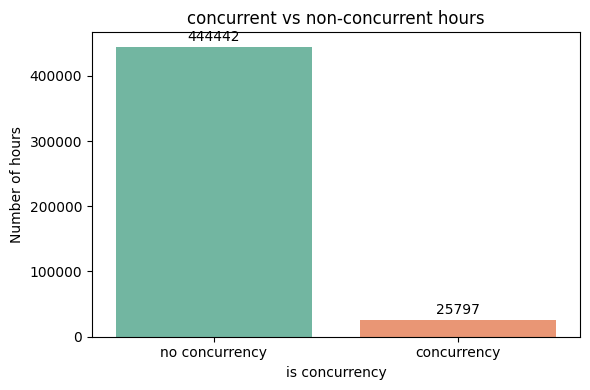

In [3]:
# Plot is_concurrency
import matplotlib.pyplot as plt
import seaborn as sns

# Convert 'cancelled' to boolean for plotting
cancel_bool = df["is_concurrency"].astype(bool)
cancel_counts = cancel_bool.value_counts().sort_index()
labels = ["no concurrency", "concurrency"]

plt.figure(figsize=(6, 4))
sns.barplot(x=labels, y=cancel_counts.values, palette="Set2")
plt.title("concurrent vs non-concurrent hours")
plt.ylabel("Number of hours")
plt.xlabel("is concurrency")
for i, v in enumerate(cancel_counts.values):
    plt.text(i, v + max(cancel_counts.values) * 0.01, str(v), ha="center", va="bottom")
plt.tight_layout()
plt.show()

In [4]:
df_processed = df.copy()
# Convert date and time columns to datetime
df_processed["date"] = pd.to_datetime(
    df_processed["date"] + " " + df_processed["hour"].astype(str) + ":00:00"
)
df_processed
# Extract time features from scheduled departure time
df_processed["dep_hour"] = df_processed["date"].dt.hour
df_processed["dep_day_of_week"] = df_processed["date"].dt.dayofweek
df_processed["dep_month"] = df_processed["date"].dt.month
df_processed["dep_day_of_year"] = df_processed["date"].dt.dayofyear

# Extract time features from scheduled arrival time
df_processed["arr_hour"] = df_processed["date"].dt.hour

# Circular encoding for time-based features
print("Creating circular encodings for time-based features...")

# Hour of day (0-23) - circular encoding
df_processed["hour_sin"] = np.sin(2 * np.pi * df_processed["dep_hour"] / 24)
df_processed["hour_cos"] = np.cos(2 * np.pi * df_processed["dep_hour"] / 24)

df_processed["day_of_week_sin"] = np.sin(
    2 * np.pi * df_processed["dep_day_of_week"] / 7
)
df_processed["day_of_week_cos"] = np.cos(
    2 * np.pi * df_processed["dep_day_of_week"] / 7
)

df_processed["month_sin"] = np.sin(2 * np.pi * df_processed["dep_month"] / 12)
df_processed["month_cos"] = np.cos(2 * np.pi * df_processed["dep_month"] / 12)

df_processed["day_of_year_sin"] = np.sin(
    2 * np.pi * df_processed["dep_day_of_year"] / 365
)
df_processed["day_of_year_cos"] = np.cos(
    2 * np.pi * df_processed["dep_day_of_year"] / 365
)

print("Circular encodings created successfully!")

df_processed["year"] = df_processed["date"].dt.year
df_processed["airport_group"] = df_processed["airport_group"].astype("category")
df_processed["is_concurrency"] = df_processed["is_concurrency"].astype("category")

Creating circular encodings for time-based features...
Circular encodings created successfully!


In [5]:
feature_columns = [
    "airport_group",
    "year",
    "hour_sin",
    "hour_cos",
    "day_of_week_sin",
    "day_of_week_cos",
    "month_sin",
    "month_cos",
    "day_of_year_sin",
    "day_of_year_cos",
    "concurrency",
    "number_of_flights",
    "overlapping_time_minutes",
    "date",
]

print(f"Total features selected: {len(feature_columns)}")


model_data = df_processed[feature_columns + ["is_concurrency"]].copy()

# Remove rows with missing values in key features
print(f"Modeling dataset shape: {model_data.shape}")

Total features selected: 14
Modeling dataset shape: (470239, 15)


In [6]:
# # Convert to H2O Frame
# print("Converting to H2O Frame...")
# h2o_frame = h2o.H2OFrame(model_data)
# # CRITICAL: Convert target to categorical for binary classification
# print("Converting target variable to categorical for binary classification...")
# h2o_frame["is_concurrency"] = h2o_frame["is_concurrency"].asfactor()
# # Also convert airport_group to categorical if it isn't already
# h2o_frame["airport_group"] = h2o_frame["airport_group"].asfactor()

# print("Data types after conversion:")
# print(h2o_frame.types)

In [ ]:
print("Splitting data with October 2024 as test set...")
temp_df = model_data.copy()

# Remove duplicates from the entire dataset first
print(f"Original dataset shape: {temp_df.shape}")
temp_df = temp_df.drop_duplicates()
print(f"After removing duplicates: {temp_df.shape}")

# Create test set: October 2024
test_mask = (temp_df["date"].dt.year == 2024) & (temp_df["date"].dt.month == 10)
test_df = temp_df[test_mask].copy()

# Create train+validation set: everything else
train_valid_df = temp_df[~test_mask].copy()

# Shuffle the train+validation data before splitting to avoid temporal bias
train_valid_df = train_valid_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Split train+validation into train and validation (80/20 split of remaining data)
train_size = int(0.9 * len(train_valid_df))
train_df = train_valid_df.iloc[:train_size]
valid_df = train_valid_df.iloc[train_size:]

# Verify no overlaps between sets
print(f"Train set shape: {train_df.shape}")
print(f"Validation set shape: {valid_df.shape}")
print(f"Test set shape: {test_df.shape}")

# Check for overlaps (optional verification)
train_dates = set(train_df["date"].dt.strftime("%Y-%m-%d %H:%M:%S"))
valid_dates = set(valid_df["date"].dt.strftime("%Y-%m-%d %H:%M:%S"))
test_dates = set(test_df["date"].dt.strftime("%Y-%m-%d %H:%M:%S"))

train_valid_overlap = len(train_dates.intersection(valid_dates))
train_test_overlap = len(train_dates.intersection(test_dates))
valid_test_overlap = len(valid_dates.intersection(test_dates))

print(
    f"Overlapping dates - Train/Valid: {train_valid_overlap}, Train/Test: {train_test_overlap}, Valid/Test: {valid_test_overlap}"
)

# Convert back to H2O frames
test = h2o.H2OFrame(test_df.drop(["date"], axis=1))
train = h2o.H2OFrame(train_df.drop(["date"], axis=1))
valid = h2o.H2OFrame(valid_df.drop(["date"], axis=1))

Splitting data with October 2024 as test set...
Original dataset shape: (470239, 15)
After removing duplicates: (470239, 15)
Train set shape: (372024, 15)
Validation set shape: (93007, 15)
Test set shape: (5208, 15)
Overlapping dates - Train/Valid: 52481, Train/Test: 0, Valid/Test: 0
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%


In [ ]:
# Convert categorical columns back to factors
test["is_concurrency"] = test["is_concurrency"].asfactor()
test["airport_group"] = test["airport_group"].asfactor()
train["is_concurrency"] = train["is_concurrency"].asfactor()
train["airport_group"] = train["airport_group"].asfactor()
valid["is_concurrency"] = valid["is_concurrency"].asfactor()
valid["airport_group"] = valid["airport_group"].asfactor()

print(f"Train set shape: {train.shape}")
print(f"Validation set shape: {valid.shape}")
print(f"Test set shape: {test.shape}")

# Define predictors and response (excluding date from features)
x = [col for col in feature_columns if col != "date"]
y = "is_concurrency"

print(f"Features (x): {x}")
print(f"Target (y): {y}")

# Verify target is categorical
print(f"Target variable type: {train[y].types}")

# Check class balance in training set
train_target_summary = train[y].table()
print(f"\nClass distribution in training set:")
print(train_target_summary)

# Initialize H2O AutoML with corrected settings for binary classification
print("\nInitializing H2O AutoML for binary classification...")
aml = H2OAutoML(
    max_models=12,
    max_runtime_secs=600,  # 10 minutes
    balance_classes=True,  # Handle class imbalance
    seed=42,
    project_name="concurrency_prediction",
    sort_metric="AUC",  # Now correct for binary classification
    # Focus on faster, stable algorithms
    include_algos=["GLM", "GBM", "XGBoost", "DRF", "StackedEnsemble", "DeepLearning"],
    nfolds=5,
    stopping_metric="AUC",
    stopping_tolerance=0.01,
    stopping_rounds=3,
    max_after_balance_size=3.0,
)

# Train AutoML models
print("Training AutoML models for binary classification...")
print("This should work now - estimated 3-5 minutes...")
aml.train(x=x, y=y, training_frame=train, validation_frame=valid)

print("\nAutoML training completed!")
print(f"Leaderboard contains {len(aml.leaderboard)} models")

Train set shape: (372024, 14)
Validation set shape: (93007, 14)
Test set shape: (5208, 14)
Features (x): ['airport_group', 'year', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'day_of_year_sin', 'day_of_year_cos', 'concurrency', 'number_of_flights', 'overlapping_time_minutes']
Target (y): is_concurrency
Target variable type: {'is_concurrency': 'enum'}

Class distribution in training set:
  is_concurrency    Count
               0   351707
               1    20317
[2 rows x 2 columns]


Initializing H2O AutoML for binary classification...
Training AutoML models for binary classification...
This should work now - estimated 3-5 minutes...
AutoML progress: |
21:06:10.938: User specified a validation frame with cross-validation still enabled. Please note that the models will still be validated using cross-validation only, the validation frame will be used to provide purely informative validation metrics on the trained models.
21:12:28.208: User sp

In [14]:
# View the leaderboard
print("AutoML Leaderboard:")
leaderboard = aml.leaderboard.as_data_frame()
print(leaderboard)

# Get the best model
best_model = aml.leader
print(f"\nBest model: {best_model.model_id}")

# Evaluate on test set
print("\nEvaluating best model on test set...")
test_performance = best_model.model_performance(test)

# Extract metrics properly - H2O returns different formats
try:
    # Try different ways to extract AUC
    auc_value = test_performance.auc()
    if isinstance(auc_value, list) and len(auc_value) > 0:
        auc_value = auc_value[0][0] if isinstance(auc_value[0], list) else auc_value[0]
    print(f"Test AUC: {auc_value:.4f}")
except:
    print("Could not extract AUC")

try:
    # Extract accuracy at different thresholds
    accuracy_data = test_performance.accuracy()
    if isinstance(accuracy_data, list) and len(accuracy_data) > 0:
        # Usually accuracy is reported at optimal threshold
        accuracy_value = (
            accuracy_data[0][1] if len(accuracy_data[0]) > 1 else accuracy_data[0]
        )
        print(f"Test Accuracy: {accuracy_value:.4f}")
    else:
        print(f"Test Accuracy: {accuracy_data:.4f}")
except:
    print("Could not extract Accuracy")

try:
    # Extract precision and recall
    precision_data = test_performance.precision()
    recall_data = test_performance.recall()

    if isinstance(precision_data, list) and len(precision_data) > 0:
        precision_value = (
            precision_data[0][1] if len(precision_data[0]) > 1 else precision_data[0]
        )
        print(f"Test Precision: {precision_value:.4f}")

    if isinstance(recall_data, list) and len(recall_data) > 0:
        recall_value = recall_data[0][1] if len(recall_data[0]) > 1 else recall_data[0]
        print(f"Test Recall: {recall_value:.4f}")
except:
    print("Could not extract Precision/Recall")

# Print confusion matrix
print("\nConfusion Matrix:")
try:
    cm = test_performance.confusion_matrix()
    print(cm)
except:
    print("Could not generate confusion matrix")

# Generate predictions on test set
print("\nGenerating predictions on test set...")
predictions = best_model.predict(test)
print("Sample predictions:")
print(predictions.head())

# Feature importance (if available)
try:
    print("\nFeature Importance:")
    importance = best_model.varimp(use_pandas=True)
    print(importance.head(10))
except:
    print("Feature importance not available for this model type")

# Print overall model performance summary
print("\nOverall Model Performance Summary:")
print(test_performance)

AutoML Leaderboard:
                              model_id       auc   logloss     aucpr  \
0       GBM_4_AutoML_1_20250924_210610  0.991049  0.061001  0.889048   
1       GBM_8_AutoML_2_20250924_211228  0.991049  0.061001  0.889048   
2       GBM_5_AutoML_2_20250924_211228  0.991004  0.067585  0.889198   
3       GBM_1_AutoML_1_20250924_210610  0.991004  0.067585  0.889198   
4       GBM_7_AutoML_2_20250924_211228  0.990641  0.062813  0.884959   
5       GBM_3_AutoML_1_20250924_210610  0.990641  0.062813  0.884959   
6   XGBoost_2_AutoML_1_20250924_210610  0.990101  0.096856  0.881497   
7   XGBoost_4_AutoML_2_20250924_211228  0.990101  0.096856  0.881497   
8   XGBoost_1_AutoML_1_20250924_210610  0.989987  0.085355  0.881207   
9   XGBoost_3_AutoML_2_20250924_211228  0.989987  0.085355  0.881207   
10      GBM_6_AutoML_2_20250924_211228  0.989508  0.066097  0.865331   
11      GBM_2_AutoML_1_20250924_210610  0.989508  0.066097  0.865331   
12      DRF_1_AutoML_1_20250924_210610  0.98

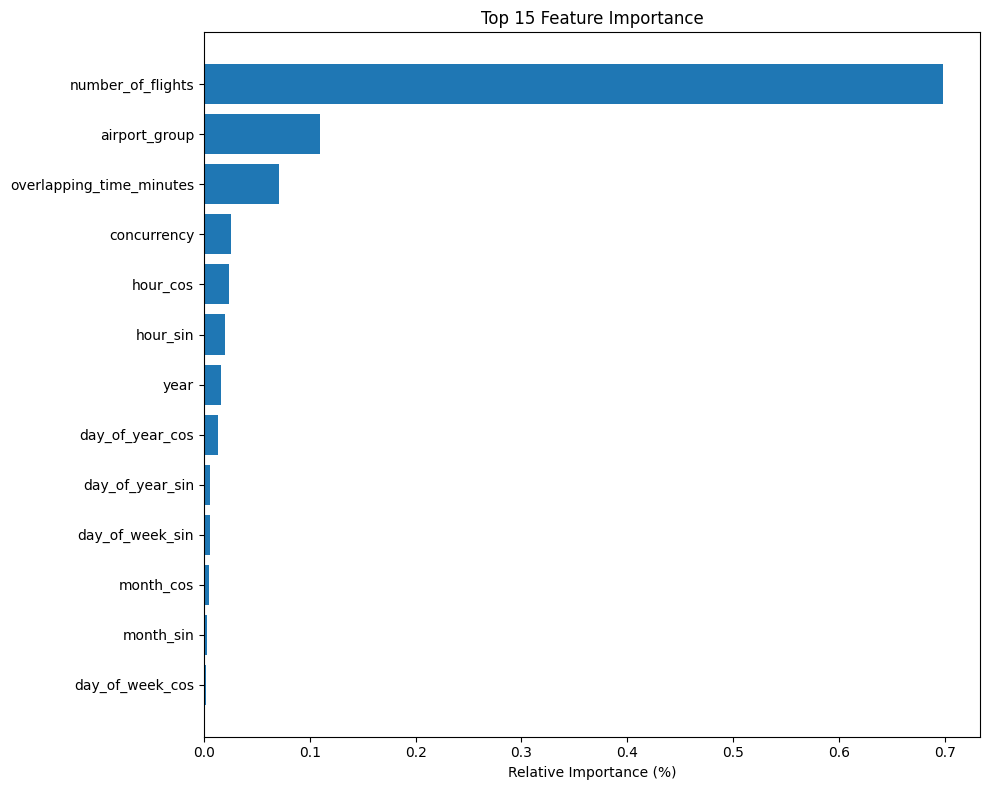

In [10]:
# Plot variable importance
varim = best_model.varimp(use_pandas=True)
plt.figure(figsize=(10, 8))
if len(varim) > 0:
    top_features = varim.head(15)
    plt.barh(range(len(top_features)), top_features["percentage"])
    plt.yticks(range(len(top_features)), top_features["variable"])
    plt.xlabel("Relative Importance (%)")
    plt.title("Top 15 Feature Importance")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("No variable importance data available")